# Proyecto final · 06 · Explicación de las correcciones

Última etapa del pipeline, la tarea complementaria de **POS tagging**. BART-large devuelve la oración corregida, pero no dice qué cambió ni por qué. Para eso:

1. **spaCy** etiqueta cada palabra de la oración original y de la corregida (categoría gramatical, etiqueta fina y lema);
2. **ERRANT** alinea las dos oraciones, extrae cada edición y le asigna un tipo usando esas etiquetas (`R:VERB:FORM`: se *reemplazó* un *verbo* por otra *forma* del mismo verbo);
3. el tipo elige una **plantilla en español**, y las etiquetas completan el detalle (qué forma verbal se pedía, qué preposición la rige);
4. cada explicación lleva una **confianza** según qué tan bien corrige el modelo ese tipo de error (notebook 05).

```mermaid
flowchart LR
    A[párrafo] -->|spaCy: oraciones| B[oración]
    B --> C[BART-large<br/>corregir.py]
    B & C -->|spaCy: POS, etiqueta, lema| D[ERRANT<br/>alinea y tipa]
    D -->|R:VERB:FORM| E[plantilla<br/>explicar.py]
    E --> F[explicación en español<br/>+ confianza]
```

Todo está en `src/explicar.py` (con tests); `corregir_y_explicar` es la función que usará la app.

In [1]:
import collections
import inspect
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import evaluacion
import explicar
from corregir import Corrector
from graficas import AZUL, TINTA_SECUNDARIA, aplicar_estilo
from IPython.display import Markdown, display
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

DATOS, FIG = RAIZ / "datos" / "procesados" / "entrenamiento", RAIZ / "figuras"
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
aplicar_estilo()
corrector = Corrector(RAIZ / "modelos" / "experimentos" / "large-3e-5" / "mejor")
anotador = explicar._anotador()
print("ERRANT con", anotador.nlp.meta["name"], anotador.nlp.meta["version"])

ERRANT con core_web_sm 3.8.0


## 1 · Una oración paso a paso

La oración de los notebooks 03 y 04 (FCE test, hispanohablante, id 30631):

In [2]:
fila = next(f for f in evaluacion.leer_conjunto(DATOS / "fce_test_es").entrada if f["id"] == 30631)
original = fila["original"]
corregida = corrector.corregir([original])[0][0]
print("original  :", original)
print("BART-large:", corregida)
print("referencia:", fila["corregida"])

original  : As you know I am in charge for organise the conference in my college. Do not worry if Richard did not left you all the information.
BART-large: As you know I am in charge of organising the conference in my college. Do not worry if Richard did not give you all the information.
referencia: As you know, I am in charge of organising the conference in my college. Do not worry if Richard did not leave you all the information.


### 1.1 · POS tagging

ERRANT analiza las dos oraciones con spaCy. Estas son las etiquetas de la parte que cambió: categoría universal (`pos`), etiqueta fina del Penn Treebank (`tag`, distingue `VB` forma base de `VBG` forma en -ing) y lema.

In [3]:
o, c = anotador.parse(original, tokenise=True), anotador.parse(corregida, tokenise=True)

def etiquetas(doc, desde, hasta):
    return pd.DataFrame([{"palabra": t.text, "pos": t.pos_, "tag": t.tag_, "lema": t.lemma_} for t in doc[desde:hasta]]).T

display(Markdown("**Original**"), etiquetas(o, 0, 10), Markdown("**Corregida**"), etiquetas(c, 0, 11))

**Original**

,0,1,2,3,4,5,6,7,8,9
palabra,As,you,know,I,am,in,charge,for,organise,the
pos,SCONJ,PRON,VERB,PRON,AUX,ADP,NOUN,ADP,NOUN,DET
tag,IN,PRP,VBP,PRP,VBP,IN,NN,IN,NN,DT
lema,as,you,know,I,be,in,charge,for,organise,the


**Corregida**

,0,1,2,3,4,5,6,7,8,9,10
palabra,As,you,know,I,am,in,charge,of,organising,the,conference
pos,SCONJ,PRON,VERB,PRON,AUX,ADP,NOUN,ADP,VERB,DET,NOUN
tag,IN,PRP,VBP,PRP,VBP,IN,NN,IN,VBG,DT,NN
lema,as,you,know,I,be,in,charge,of,organise,the,conference


### 1.2 · Alineación y tipo

ERRANT alinea las dos secuencias de tokens (como un diff, pero con costos que prefieren emparejar palabras con el mismo lema o la misma categoría) y luego tipa cada diferencia con reglas sobre las etiquetas de arriba:

- *for → of*: las dos son `ADP`, así que es `R:PREP`.
- *organise → organising*: el error confunde al etiquetador, que lee *organise* tras *for* como sustantivo (`NN`). ERRANT no se deja engañar porque compara el **lema** (*organise* en ambas) y la etiqueta de la palabra corregida (`VBG`): mismo verbo, otra forma, así que es `R:VERB:FORM`. Es la inestabilidad que midió el análisis P2 del notebook 02, y la razón de tipar con las dos oraciones y no solo con la original.
- *left → give*: dos verbos con lema distinto, así que es `R:VERB` (otra palabra).

In [4]:
pd.DataFrame([{"tokens": f"{e.o_start}–{e.o_end}", "original": e.o_str, "corregido": e.c_str, "tipo": e.type,
               "pos original": " ".join(t.pos_ for t in e.o_toks), "pos corregido": " ".join(t.pos_ for t in e.c_toks),
               "tag original": " ".join(t.tag_ for t in e.o_toks), "tag corregido": " ".join(t.tag_ for t in e.c_toks)}
              for e in anotador.annotate(o, c)])

,tokens,original,corregido,tipo,pos original,pos corregido,tag original,tag corregido
0,7–8,for,of,R:PREP,ADP,ADP,IN,IN
1,8–9,organise,organising,R:VERB:FORM,NOUN,VERB,NN,VBG
2,22–23,left,give,R:VERB,VERB,VERB,VBN,VB


### 1.3 · Plantilla

El tipo elige la plantilla en `explicar.PLANTILLAS`; si el tipo no tiene una propia, se usa la genérica de su operación (*falta*, *sobra*, *cambia*). La de `R:VERB:FORM` usa otra vez el POS tagging: lee la etiqueta fina del verbo corregido para nombrar la forma y mira la palabra anterior; si es una preposición (`ADP`), explica la regla del -ing.

In [5]:
print(inspect.getsource(explicar._forma_verbal))

def _forma_verbal(e):
    c = _verbo(e.c_toks)
    forma = FORMAS.get(c.tag_, "otra forma")
    texto = f"Aquí va {forma} del verbo: «{e.c_str}» en lugar de «{e.o_str}»."
    anterior = _anterior(e.c_toks)
    if c.tag_ == "VBG" and anterior is not None and anterior.pos_ == "ADP":
        texto += f" Después de una preposición («{anterior.text}») el verbo va en -ing."
    elif c.tag_ == "VB" and anterior is not None and (anterior.lower_ == "to" or anterior.tag_ == "MD"):
        texto += f" Después de «{anterior.text}» va la forma base, sin -s, -ing ni -ed."
    return texto



In [6]:
for e in explicar.explicar(original, corregida):
    print(f"[{e.confianza:>5}] {e.tipo:<12} «{e.original}» → «{e.corregido}»\n        {e.explicacion}")

[media] R:PREP       «for» → «of»
        La preposición correcta es «of», no «for». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que las rige.
[ alta] R:VERB:FORM  «organise» → «organising»
        Aquí va la forma en -ing del verbo: «organising» en lugar de «organise». Después de una preposición («of») el verbo va en -ing.
[ baja] R:VERB       «left» → «give»
        Sugerencia de vocabulario: «give» (verbo) expresa mejor la idea que «left».


Cada edición sale con su posición en tokens de la oración original (`inicio`, `fin`), para que la app la subraye, y con su confianza:

- `R:VERB:FORM` es un tipo que el modelo corrige bien (F0.5 0,71 en FCE test), así que la explicación se presenta como regla (*alta*).
- `R:VERB` es elección de palabra (F0.5 0,32) y sale como *sugerencia*. Aquí la confianza baja acierta: el modelo cambió *left* por *give*, mientras que la referencia pide *leave* (el error era la forma, *did not left* → *did not leave*). La sugerencia es gramatical, pero cambia el sentido.

## 2 · Cobertura con salidas reales

El análisis P4 del notebook 02 mostró que 25 tipos cubren el 90 % de las ediciones de los anotadores. Aquí se mide sobre lo que el sistema realmente va a explicar: las ediciones que ERRANT extrae de las 2.695 salidas de BART-large en FCE test.

In [7]:
fce_test = evaluacion.leer_conjunto(DATOS / "fce_test")
originales = [f["original"] for f in fce_test.entrada]
salidas = corrector.corregir(originales)[0]
ediciones = [(o, e) for o, s in zip(originales, salidas) for e in explicar.explicar(o, s)]
conteo = collections.Counter(e.tipo for _, e in ediciones)
propias = sum(n for t, n in conteo.items() if t in explicar.PLANTILLAS)
print(f"{len(ediciones)} ediciones en {sum(o != s for o, s in zip(originales, salidas))} oraciones cambiadas")
print(f"{len(conteo)} tipos distintos; {len(explicar.PLANTILLAS)} con plantilla propia")
print(f"con plantilla propia: {propias} ({propias / len(ediciones):.1%}); genérica: {len(ediciones) - propias}")

2890 ediciones en 1405 oraciones cambiadas
51 tipos distintos; 28 con plantilla propia
con plantilla propia: 2642 (91.4%); genérica: 248


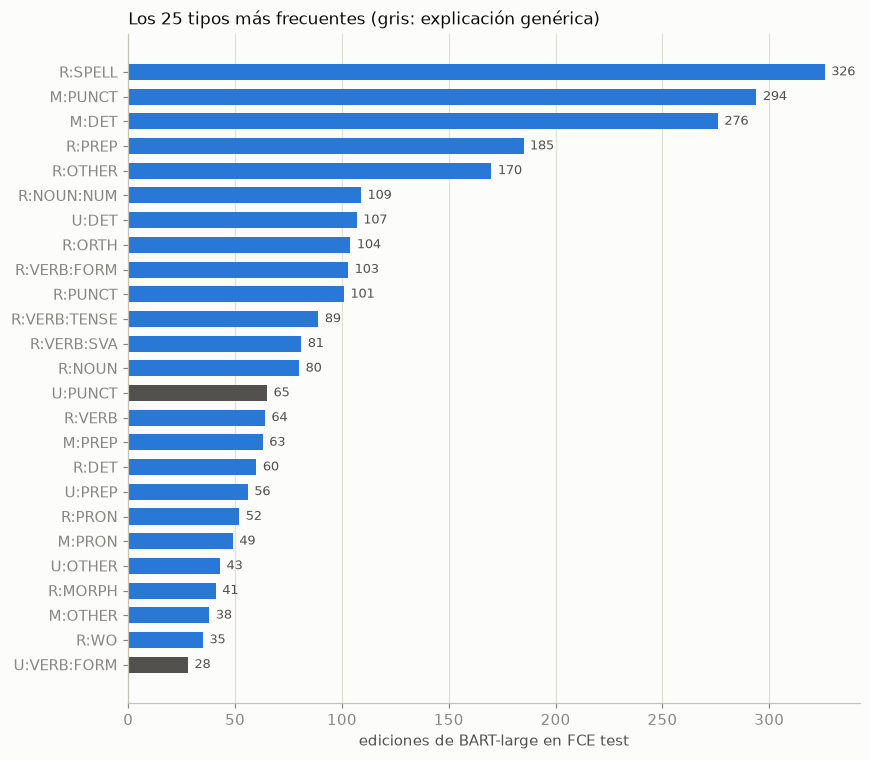

In [8]:
top = pd.Series(conteo).sort_values(ascending=True).tail(25)
fig, ax = plt.subplots(figsize=(8, 7))
colores = [AZUL if t in explicar.PLANTILLAS else TINTA_SECUNDARIA for t in top.index]
ax.barh(top.index, top.values, color=colores, height=0.65)
for i, n in enumerate(top.values):
    ax.text(n + 3, i, f"{n}", va="center", fontsize=8.5, color=TINTA_SECUNDARIA)
ax.set(xlabel="ediciones de BART-large en FCE test", title="Los 25 tipos más frecuentes (gris: explicación genérica)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "19_cobertura_plantillas.png")
plt.show()

Un ejemplo real por tipo, de los más frecuentes:

In [9]:
vistos, filas = set(), []
for o, e in ediciones:
    if e.tipo not in vistos and len(e.original) + len(e.corregido) > 1:
        vistos.add(e.tipo)
        filas.append({"tipo": e.tipo, "n": conteo[e.tipo], "confianza": e.confianza, "cambio": f"{e.original} → {e.corregido}", "explicación": e.explicacion})
pd.DataFrame(filas).sort_values("n", ascending=False).head(20).set_index("tipo")

,n,confianza,cambio,explicación
tipo,,,,
R:SPELL,326,alta,Appart → Apart,Ortografía: «Appart» se escribe «Apart».
M:PUNCT,294,media,it → . It,Falta «.»: aquí termina una oración y la siguiente empieza con mayúscula («It»).
M:DET,276,alta,→ an,"Falta el artículo «an». En inglés los sustantivos contables en singular necesitan artículo (a, an, the) o un determinante."
R:PREP,185,media,on → in,"La preposición correcta es «in», no «on». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que la..."
R:OTHER,170,baja,", → and","Sugerencia de redacción: «,» → «and»."
R:NOUN:NUM,109,alta,computer → computers,Va en plural: «computers» en lugar de «computer».
U:DET,107,alta,the →,"Sobra «the». En inglés no se pone artículo a los sustantivos usados en sentido general («la gente» → «people», «la música» → «music»), como sí se hace en es..."
R:ORTH,104,alta,internet → Internet,"«Internet» va con mayúscula. En inglés la llevan también los días, meses, idiomas, nacionalidades y el pronombre «I»."
R:VERB:FORM,103,alta,rely → relying,Aquí va la forma en -ing del verbo: «relying» en lugar de «rely».


In [10]:
por_confianza = pd.Series(collections.Counter(e.confianza for _, e in ediciones)).reindex(["alta", "media", "baja"])
pd.DataFrame({"ediciones": por_confianza, "%": (100 * por_confianza / por_confianza.sum()).round(1)})

,ediciones,%
alta,1242,43.0
media,1118,38.7
baja,530,18.3


**Confianza.** Sale del F0.5 por tipo del notebook 05: *alta* para los tipos con F0.5 ≥ 0,63 (ortografía, concordancia, forma verbal, número, morfología, mayúsculas, artículos), *baja* para los de elección de palabra y reescrituras (≤ 0,32), *media* para el resto. La app puede mostrar las de confianza baja como "sugerencia" en lugar de "error".

## 3 · Hispanohablantes: lo que verá el usuario

Oraciones de `fce_test_es` con dos o más correcciones, tal como las mostraría la app:

In [11]:
def mostrar(resultado):
    partes = []
    for r in resultado:
        if not r["ediciones"]:
            continue
        partes.append(f"> {r['original']}\n>\n> **{r['corregida']}**\n")
        for e in r["ediciones"]:
            marca = {"alta": "🟢", "media": "🟡", "baja": "⚪ sugerencia ·"}[e.confianza]
            cambio = f"~~{e.original}~~ → **{e.corregido}**" if e.original and e.corregido else (f"+ **{e.corregido}**" if e.corregido else f"~~{e.original}~~")
            partes.append(f"- {marca} {cambio} — {e.explicacion} `{e.tipo}`")
        partes.append("")
    display(Markdown("\n".join(partes)))

es = evaluacion.leer_conjunto(DATOS / "fce_test_es")
es_orig = [f["original"] for f in es.entrada]
es_salida = corrector.corregir(es_orig)[0]
es_res = [{"original": o, "corregida": s, "ediciones": explicar.explicar(o, s)} for o, s in zip(es_orig, es_salida)]
mostrar([r for r in es_res if len(r["ediciones"]) >= 2 and len(r["original"]) < 160][:6])

> As you know I am in charge for organise the conference in my college. Do not worry if Richard did not left you all the information.
>
> **As you know I am in charge of organising the conference in my college. Do not worry if Richard did not give you all the information.**

- 🟡 ~~for~~ → **of** — La preposición correcta es «of», no «for». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que las rige. `R:PREP`
- 🟢 ~~organise~~ → **organising** — Aquí va la forma en -ing del verbo: «organising» en lugar de «organise». Después de una preposición («of») el verbo va en -ing. `R:VERB:FORM`
- ⚪ sugerencia · ~~left~~ → **give** — Sugerencia de vocabulario: «give» (verbo) expresa mejor la idea que «left». `R:VERB`

> We looked in every hotel in Town trying to give you the best offerd.
>
> **We looked in every hotel in town trying to give you the best offer.**

- 🟢 ~~Town~~ → **town** — «town» va con minúscula. `R:ORTH`
- 🟢 ~~offerd~~ → **offer** — Ortografía: «offerd» se escribe «offer». `R:SPELL`

> Finally, the last day I sugget you to go to the mall where you can enjoy shopping and looking around.
>
> **Finally, on the last day I suggest you go to the mall where you can enjoy shopping and looking around.**

- 🟡 + **on** — Falta la preposición «on». `M:PREP`
- 🟢 ~~sugget~~ → **suggest** — Ortografía: «sugget» se escribe «suggest». `R:SPELL`
- 🟢 ~~to~~ — Sobra «to». `U:VERB:FORM`

> I asked to some pleople in town and this was the best place to choose.
>
> **I asked some people in town and this was the best place to choose.**

- 🟡 ~~to~~ — Sobra la preposición «to». `U:PREP`
- 🟢 ~~pleople~~ → **people** — Ortografía: «pleople» se escribe «people». `R:SPELL`

> Is situated in the top of a little mountain in the "old" part on the city.
>
> **It is situated on the top of a little mountain in the "old" part of the city.**

- 🟡 ~~Is~~ → **It is** — Falta el sujeto «It». En inglés el sujeto no se omite aunque el verbo ya lo indique («es grande» → «it is big»). `M:PRON`
- 🟡 ~~in~~ → **on** — La preposición correcta es «on», no «in». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que las rige. `R:PREP`
- 🟡 ~~on~~ → **of** — La preposición correcta es «of», no «on». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que las rige. `R:PREP`

> On the whole this is the best building in Acapulco for his history and reputation.
>
> **On the whole, this is the best building in Acapulco because of its history and reputation.**

- 🟡 + **,** — Falta «,». En inglés la coma separa las expresiones introductorias y las oraciones unidas por conjunción («As you know, …»). `M:PUNCT`
- 🟡 + **because** — Falta la preposición «because». `M:PREP`
- 🟡 ~~for~~ → **of** — La preposición correcta es «of», no «for». Las preposiciones no se traducen palabra por palabra del español: conviene aprenderlas junto con la palabra que las rige. `R:PREP`
- 🟢 ~~his~~ → **its** — El determinante que corresponde es «its», no «his». `R:DET`


In [12]:
es_conteo = collections.Counter(e.tipo for r in es_res for e in r["ediciones"])
pd.DataFrame([{"tipo": t, "ediciones": n, "plantilla": "propia" if t in explicar.PLANTILLAS else "genérica"}
              for t, n in es_conteo.most_common(10)]).set_index("tipo")

,ediciones,plantilla
tipo,,
R:SPELL,69,propia
M:PUNCT,37,propia
R:OTHER,34,propia
R:ORTH,24,propia
R:PREP,18,propia
R:VERB:FORM,18,propia
R:PUNCT,18,propia
R:VERB:SVA,14,propia
R:VERB:TENSE,13,propia


Entre los hispanohablantes dominan la ortografía, la puntuación, las mayúsculas y las preposiciones, todas con plantilla propia. El notebook 01 encontró que este grupo omite el pronombre (×1,74) y falla la puntuación (×1,69) más que el resto; por eso `M:PRON` (*Is situated* → *It is situated*) y `R:PUNCT` (coma entre dos oraciones) explican el contraste con el español en lugar de solo nombrar el cambio.

## 4 · Demo: un texto propio

`corregir_y_explicar` es el pipeline completo de la app: divide el párrafo en oraciones con spaCy, corrige cada una con BART-large y explica cada edición. Cambia `texto` y vuelve a ejecutar la celda.

In [13]:
texto = ("Yesterday I go to the cinema with my friends. Is a very good film, I recommend you to see it. "
         "The people in my city is very friendly and they likes the football.")
mostrar(explicar.corregir_y_explicar(corrector, texto))

> Yesterday I go to the cinema with my friends.
>
> **Yesterday I went to the cinema with my friends.**

- 🟡 ~~go~~ → **went** — Tiempo verbal: «go» → «went» (del presente sin -s al pasado). Revisa cuándo ocurre la acción. `R:VERB:TENSE`

> Is a very good film, I recommend you to see it.
>
> **It is a very good film. I recommend you to see it.**

- 🟡 ~~Is~~ → **It is** — Falta el sujeto «It». En inglés el sujeto no se omite aunque el verbo ya lo indique («es grande» → «it is big»). `M:PRON`
- 🟡 ~~,~~ → **.** — En inglés dos oraciones completas no se unen con coma, como se hace a menudo en español: se separan con punto. `R:PUNCT`

> The people in my city is very friendly and they likes the football.
>
> **The people in my city are very friendly and they like football.**

- 🟢 ~~is~~ → **are** — Concordancia: «is» → «are»; con sujeto plural o con I, you, we, they el presente no lleva -s. `R:VERB:SVA`
- 🟢 ~~likes~~ → **like** — Concordancia: «likes» → «like»; con sujeto plural o con I, you, we, they el presente no lleva -s. `R:VERB:SVA`
- 🟢 ~~the~~ — Sobra «the». En inglés no se pone artículo a los sustantivos usados en sentido general («la gente» → «people», «la música» → «music»), como sí se hace en español. `U:DET`


## 5 · Límites

- **La explicación es tan buena como la corrección.** Si BART-large hace un cambio innecesario (un FP del notebook 05), la plantilla lo explica igual de convencida; la confianza por tipo es la defensa: los tipos con más FP son los de confianza baja.
- **ERRANT junta ediciones vecinas.** `Is → It is` llega como una sola edición `M:PRON` y `, it → . It` como `R:PUNCT`; las plantillas buscan dentro del fragmento el pronombre, el artículo o el signo que importa (tests en `tests/test_explicar.py`).
- **El POS tagging se equivoca con palabras mal escritas o en mayúscula.** Una palabra común con mayúscula puede salir como nombre propio; la plantilla de `R:MORPH` no nombra categorías en ese caso.
- **Las plantillas explican el tipo, no el caso.** `R:PREP` dice qué preposición va, pero no por qué *in charge* pide *of*; eso requeriría un diccionario de regímenes o un modelo generativo, fuera del alcance.

## Resumen

| | |
|---|---|
| Entrada | la oración original y la corregida por BART-large |
| POS tagging | spaCy `en_core_web_sm` etiqueta ambas (pos, tag, lema); ERRANT 3.0.2 alinea y tipa cada edición con esas etiquetas |
| Explicación | 28 plantillas propias en español + una genérica por operación; las plantillas usan las etiquetas para precisar (forma verbal, preposición previa, categoría) |
| Cobertura | 91,4 % de las 2.890 ediciones de BART-large en FCE test tienen plantilla propia |
| Confianza | alta 43 % · media 39 % · baja (sugerencia) 18 %, según el F0.5 por tipo del notebook 05 |
| Para la app | `explicar.corregir_y_explicar(corrector, texto)`: párrafo → oraciones → corrección → ediciones con posición, tipo, explicación y confianza |